In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import pickle

In [2]:
%%time
df= pd.read_csv("New_Bitext_Sample_Customer_Support_Training_Dataset_27K_responses_with_paraphrases.csv", low_memory=False)

CPU times: total: 891 ms
Wall time: 982 ms


In [3]:
df.head(50)

In [4]:
df.tail(50)

In [5]:
df.shape

(26872, 6)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
 5   Paraphrase   26872 non-null  object
dtypes: object(6)
memory usage: 1.2+ MB


In [7]:
# check the columns in data
df.columns

Index(['flags', 'instruction', 'category', 'intent', 'response', 'Paraphrase'], dtype='object')

In [8]:
df.describe()

In [9]:
# check for some null or missing values in our dataset
df.isna().sum().to_numpy()

array([0, 0, 0, 0, 0, 0], dtype=int64)

In [10]:
# checking the duplicate roes in the data
duplicate_rows= df[df.duplicated()]

# print the duplicate rows
print("numbers of duplicates rows:" , duplicate_rows.shape)

numbers of duplicates rows: (0, 6)


In [11]:
# Verify the changes
df['intent'].value_counts()

intent
edit_account                1000
switch_account              1000
check_invoice               1000
complaint                   1000
contact_customer_service    1000
delivery_period              999
registration_problems        999
check_payment_methods        999
contact_human_agent          999
payment_issue                999
newsletter_subscription      999
get_invoice                  999
place_order                  998
cancel_order                 998
track_refund                 998
change_order                 997
get_refund                   997
create_account               997
check_refund_policy          997
review                       997
set_up_shipping_address      997
delivery_options             995
delete_account               995
recover_password             995
track_order                  995
change_shipping_address      973
check_cancellation_fee       950
Name: count, dtype: int64

In [12]:
#import pandas as pd
#from nltk.corpus import wordnet

# Sample function to generate a paraphrase using synonyms from WordNet
#def get_synonyms(word):
    #synonyms = []
    #for syn in wordnet.synsets(word):
        #for lemma in syn.lemmas():
            #synonyms.append(lemma.name())
    #return set(synonyms)

#def paraphrase_sentence(sentence):
    #words = sentence.split()
    #paraphrased_sentence = []
    
    #for word in words:
        #synonyms = get_synonyms(word)
        #if synonyms:
            #paraphrased_sentence.append(list(synonyms)[0])
        #else:
            #paraphrased_sentence.append(word)
    
    #return ' '.join(paraphrased_sentence)

# Load the dataset
#df = pd.read_csv("Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv", low_memory=False)

# Create a new column 'Paraphrase' by paraphrasing the 'intent' column
#df['Paraphrase'] = df['response'].apply(paraphrase_sentence)

# Display the original and paraphrased intent
#df.head(10)

# Save the updated DataFrame to a new CSV file
#df.to_csv("New_Bitext_Sample_Customer_Support_Training_Dataset_27K_responses_with_paraphrases.csv", index=False)

In [13]:
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Text cleaning function (optional, based on data quality)
def clean_text(text):
    text = re.sub(r'{{.*?}}', '', text)  # Removing placeholders like {{Order Number}}
    text = re.sub(r'\s+', ' ', text).strip()  # Removing extra spaces
    return text

# Apply the clean_text function to the relevant columns
df[['instruction', 'response', 'Paraphrase']] = df[['instruction', 'response', 'Paraphrase']].applymap(clean_text)

# Tokenization
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(df['instruction'].tolist() + df['response'].tolist() + df['Paraphrase'].tolist())

# Convert text to sequences
instruction_sequences = tokenizer.texts_to_sequences(df['instruction'])
response_sequences = tokenizer.texts_to_sequences(df['response'])
paraphrase_sequences = tokenizer.texts_to_sequences(df['Paraphrase'])

# Padding sequences
padded_instruction_sequences = pad_sequences(instruction_sequences, maxlen=100, padding='post', truncating='post')
padded_response_sequences = pad_sequences(response_sequences, maxlen=100, padding='post', truncating='post')
padded_paraphrase_sequences = pad_sequences(paraphrase_sequences, maxlen=100, padding='post', truncating='post')

# Combine padded sequences if needed (example: concatenate them or choose one of them)
X = padded_instruction_sequences  # You can choose how to combine these sequences

# Label Encoding the intent
label_encoder = LabelEncoder()
df['intent_encoded'] = label_encoder.fit_transform(df['intent'])

# Verify the changes
df['intent_encoded'].value_counts()

C:\Users\user\AppData\Local\Temp\ipykernel_3516\3051990998.py:14: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df[['instruction', 'response', 'Paraphrase']] = df[['instruction', 'response', 'Paraphrase']].applymap(clean_text)


intent_encoded
14    1000
24    1000
4     1000
7     1000
8     1000
13     999
21     999
5      999
9      999
18     999
17     999
15     999
19     998
0      998
26     998
1      997
16     997
10     997
6      997
22     997
23     997
12     995
11     995
20     995
25     995
2      973
3      950
Name: count, dtype: int64

In [14]:
import joblib

# Save the label encoder
joblib.dump(label_encoder, 'label_encoder.pkl')

['label_encoder.pkl']

In [15]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, df[['intent_encoded']], test_size=0.3, random_state=42)

# Check the shapes of the resulting datasets
print(f"Training data shape: {X_train.shape}")
print(f"Test data shape: {X_test.shape}")

Training data shape: (18810, 100)
Test data shape: (8062, 100)


In [16]:
import tensorflow as tf
from tensorflow.keras.layers import Dropout, Embedding, LSTM, Dense
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential

# Set the random seed for reproducibility
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(10000, 64, input_length=100),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(df['intent_encoded'].nunique(), activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Training the model
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test), verbose=2)

Epoch 1/10
588/588 - 12s - loss: 2.7625 - accuracy: 0.2163 - val_loss: 1.4933 - val_accuracy: 0.6176 - 12s/epoch - 20ms/step
Epoch 2/10
588/588 - 10s - loss: 0.9396 - accuracy: 0.7717 - val_loss: 0.5940 - val_accuracy: 0.8708 - 10s/epoch - 17ms/step
Epoch 3/10
588/588 - 10s - loss: 0.4311 - accuracy: 0.9082 - val_loss: 0.3277 - val_accuracy: 0.9279 - 10s/epoch - 17ms/step
Epoch 4/10
588/588 - 10s - loss: 0.2578 - accuracy: 0.9439 - val_loss: 0.2491 - val_accuracy: 0.9424 - 10s/epoch - 18ms/step
Epoch 5/10
588/588 - 9s - loss: 0.1779 - accuracy: 0.9620 - val_loss: 0.1767 - val_accuracy: 0.9634 - 9s/epoch - 16ms/step
Epoch 6/10
588/588 - 10s - loss: 0.1328 - accuracy: 0.9727 - val_loss: 0.1470 - val_accuracy: 0.9696 - 10s/epoch - 17ms/step
Epoch 7/10
588/588 - 9s - loss: 0.1036 - accuracy: 0.9806 - val_loss: 0.1295 - val_accuracy: 0.9725 - 9s/epoch - 16ms/step
Epoch 8/10
588/588 - 15s - loss: 0.0817 - accuracy: 0.9843 - val_loss: 0.1150 - val_accuracy: 0.9747 - 15s/epoch - 25ms/step
Epoc

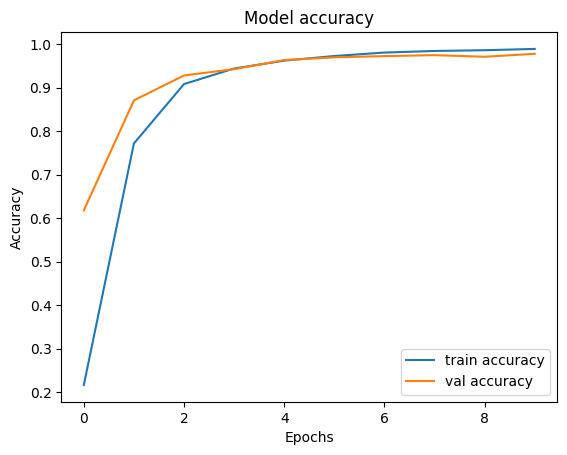

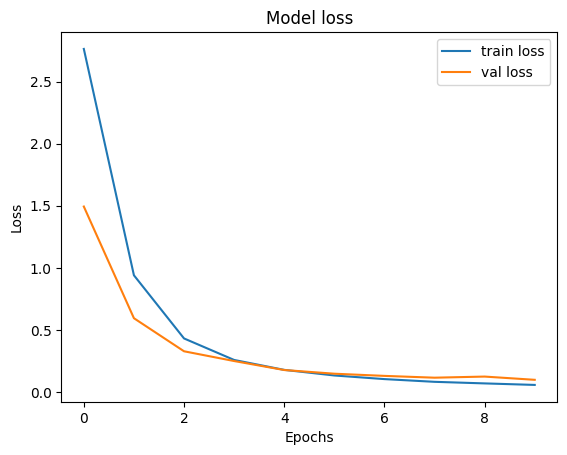

In [17]:
# Plotting the training history
import matplotlib.pyplot as plt

# Plotting the training history
import matplotlib.pyplot as plt

# Plot accuracy
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.title('Model accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot loss
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.title('Model loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

252/252 [==============================] - 1s 2ms/step
Classification Report:
                           precision    recall  f1-score   support

            cancel_order       0.95      0.97      0.96       286
            change_order       0.92      0.97      0.95       274
 change_shipping_address       0.98      0.97      0.98       308
  check_cancellation_fee       0.96      0.99      0.98       301
           check_invoice       0.98      0.97      0.97       300
   check_payment_methods       1.00      0.98      0.99       283
     check_refund_policy       1.00      0.97      0.98       311
               complaint       0.99      1.00      0.99       289
contact_customer_service       0.99      0.99      0.99       316
     contact_human_agent       1.00      0.97      0.98       304
          create_account       0.94      0.97      0.96       314
          delete_account       1.00      0.96      0.98       277
        delivery_options       0.93      0.98      0.96       

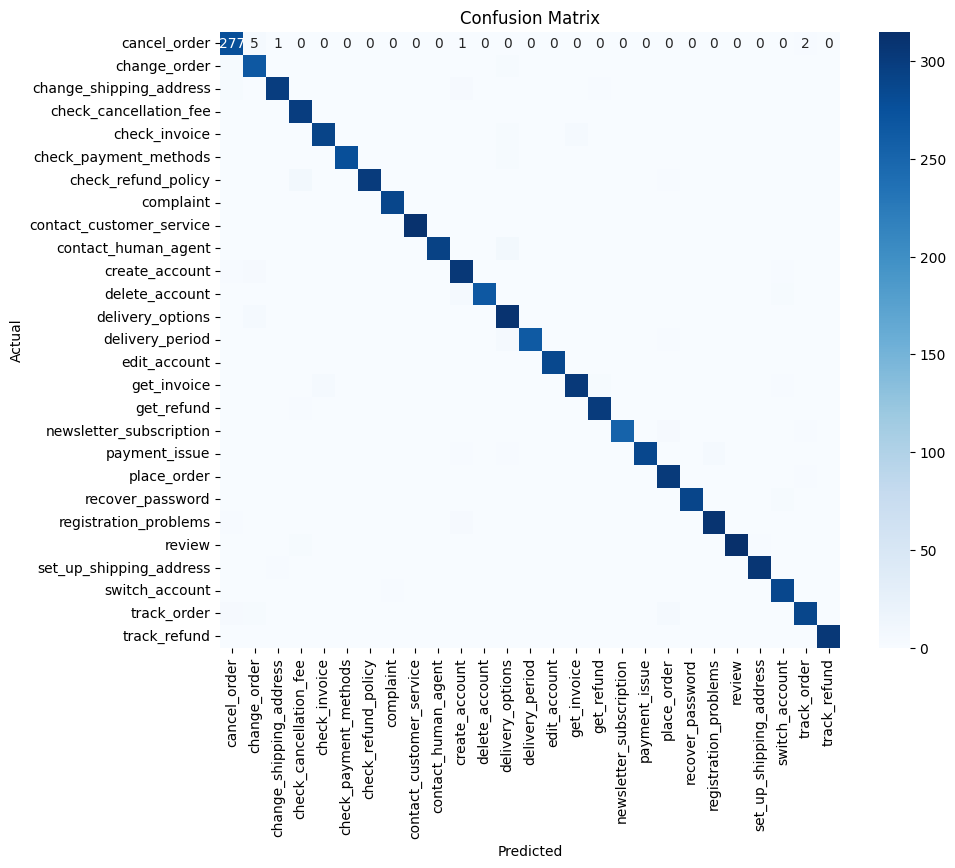

C:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [18]:
# Generate predictions
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Classification report
print("Classification Report:\n", classification_report(y_test, y_pred_classes, target_names=label_encoder.classes_))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Save the improved model and tokenizer
model.save('improved_intent_detection_model.h5')

with open('tokenizer.pickle', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)


In [9]:
import tensorflow as tf
import pickle
import numpy as np
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Define paths to your saved model and tokenizer
model_path = 'improved_intent_detection_model.h5'
tokenizer_path = 'tokenizer.pickle'
max_sequence_length = 100  # Replace with the actual max sequence length used during training

# Define your intent labels according to the encoded values
intent_labels = [
    "edit_account",                # 0
    "switch_account",              # 1
    "check_invoice",               # 2
    "complaint",                   # 3
    "contact_customer_service",    # 4
    "delivery_period",             # 5
    "registration_problems",       # 6
    "check_payment_methods",       # 7
    "contact_human_agent",         # 8
    "payment_issue",               # 9
    "newsletter_subscription",     # 10
    "get_invoice",                 # 11
    "place_order",                 # 12
    "cancel_order",                # 13
    "track_refund",                # 14
    "change_order",                # 15
    "get_refund",                  # 16
    "create_account",              # 17
    "check_refund_policy",         # 18
    "review",                      # 19
    "set_up_shipping_address",     # 20
    "delivery_options",            # 21
    "delete_account",              # 22
    "recover_password",            # 23
    "track_order",                 # 24
    "change_shipping_address",     # 25
    "check_cancellation_fee"       # 26
]

# Load the trained model
model = tf.keras.models.load_model(model_path)

# Load the tokenizer
with open(tokenizer_path, 'rb') as handle:
    tokenizer = pickle.load(handle)

def clean_text(text):
    text = re.sub(r'{{.*?}}', '', text)  # Removing placeholders like {{Order Number}}
    text = re.sub(r'\s+', ' ', text).strip()  # Removing extra spaces
    return text

def predict_intent(user_input):
    # Preprocess the input text
    user_input_cleaned = clean_text(user_input)
    sequences = tokenizer.texts_to_sequences([user_input_cleaned])
    padded_sequences = pad_sequences(sequences, maxlen=max_sequence_length)

    # Predict the intent
    predictions = model.predict(padded_sequences)
    
    # Print the shape of predictions and the raw prediction values
    print(f"Predictions shape: {predictions.shape}")
    print(f"Raw predictions: {predictions}")

    # Decode the prediction to intent index
    intent_index = np.argmax(predictions)
    
    # Print the predicted intent index
    print(f"The predicted intent index is: {intent_index}")
    return intent_index

# Example usage
user_input = "ace fthm that you follow try_on to obtain compensation for your money. IT hindquarters follow queer when you sense corresponding you're owe just_about physique of compensation. To assistance you better, could you delight put_up Pine_Tree_State with more item just_about the situation? This volition enable Pine_Tree_State to conduct you through_with the requisite measure to petition the compensation you follow seeking. rest insure that I'll fare my just to insure you obtain the bread_and_butter you ask IN this process."
predicted_intent_index = predict_intent(user_input)

1/1 [==============================] - 0s 105ms/step
Predictions shape: (1, 27)
Raw predictions: [[9.7091346e-10 2.1021604e-17 2.8828612e-08 5.2694738e-01 1.1098511e-23
  3.8237817e-17 5.9474733e-06 4.1246871e-04 7.9044141e-16 1.3371465e-26
  8.6071490e-14 2.4539981e-09 9.1393441e-18 2.5603722e-14 1.1060442e-21
  1.4662299e-24 1.6586812e-03 7.3771271e-06 9.9409901e-29 3.2481654e-07
  9.4242031e-19 4.0425879e-24 3.1962499e-01 5.6853156e-07 5.1203983e-09
  8.4793239e-05 1.5125744e-01]]
The predicted intent index is: 3
